In [4]:
using LinearAlgebra
using SparseArrays
using Random
using ITensorMPS
using ITensors
using Interpolations
using JLD2

#To get the exact Eigen Space for Comparison
function TrueEigenSpace(Operator::Tuple{Vector,Vector,Vector},num_Qbits::Int,dim::Int) 
    N,d=num_Qbits,dim
    a,b,c=Operator
    M=zeros((d^N,d^N))
    for j in 1:d^N -1
        M[j,j]=a[j]
        M[j,j+1]=b[j]
        M[j+1,j]=c[j]
    end
    M[d^N,d^N]=a[d^N]
    E=eigen(M)
    permutation=sortperm(abs.(E.values))
    psi=E.vectors[:,permutation]
    lambda=E.values[permutation]
    return lambda,psi'
end

function TrueEigenSpace(Operator::Tuple{Number,Number,Number},num_Qbits::Int,dim::Int) 
    N,d=num_Qbits,dim
    a,b,c=Operator   
    M=zeros((d^N,d^N))
    for j in 1:d^N -1
        M[j,j]=a
        M[j,j+1]=b
        M[j+1,j]=c
    end
    M[d^N,d^N]=a
    E=eigen(M)
    permutation=sortperm(abs.(E.values))
    psi=E.vectors[:,permutation]
    lambda=E.values[permutation]
    return lambda,psi'
end

TrueEigenSpace (generic function with 2 methods)

In [ ]:
using JLD2
using LinearAlgebra
using CairoMakie

Num    = 10
Nmodes = 50

steps  = 20000

fileXvec = "AnhoXvec_$(Num)Qubit_dt0.1_Steps$(steps).jld2"
fileYvec = "AnhoYvec_$(Num)Qubit_dt0.1_Steps$(steps).jld2"


@load fileXvec Ψ_x
@load fileYvec Ψ_y

ΨX = Ψ_x[ 1:2]   # first two modes
ΨY = Ψ_y[ 1:2]

Nx = 2^10
Ny = 2^10


function product2D(ψx, ψy)
    ψ = zeros(Float64, Nx, Ny)
    for i in 1:Nx
        for j in 1:Ny
            ψ[i,j] = real(ψx[i] * ψy[j]')
        end
    end
    return ψ ./ norm(ψ)
end

ψ11 = product2D(ΨX[1], ΨY[1])
ψ12 = product2D(ΨX[1], ΨY[2])
ψ21 = product2D(ΨX[2], ΨY[1])
ψ22 = product2D(ΨX[2], ΨY[2])

print("done")

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


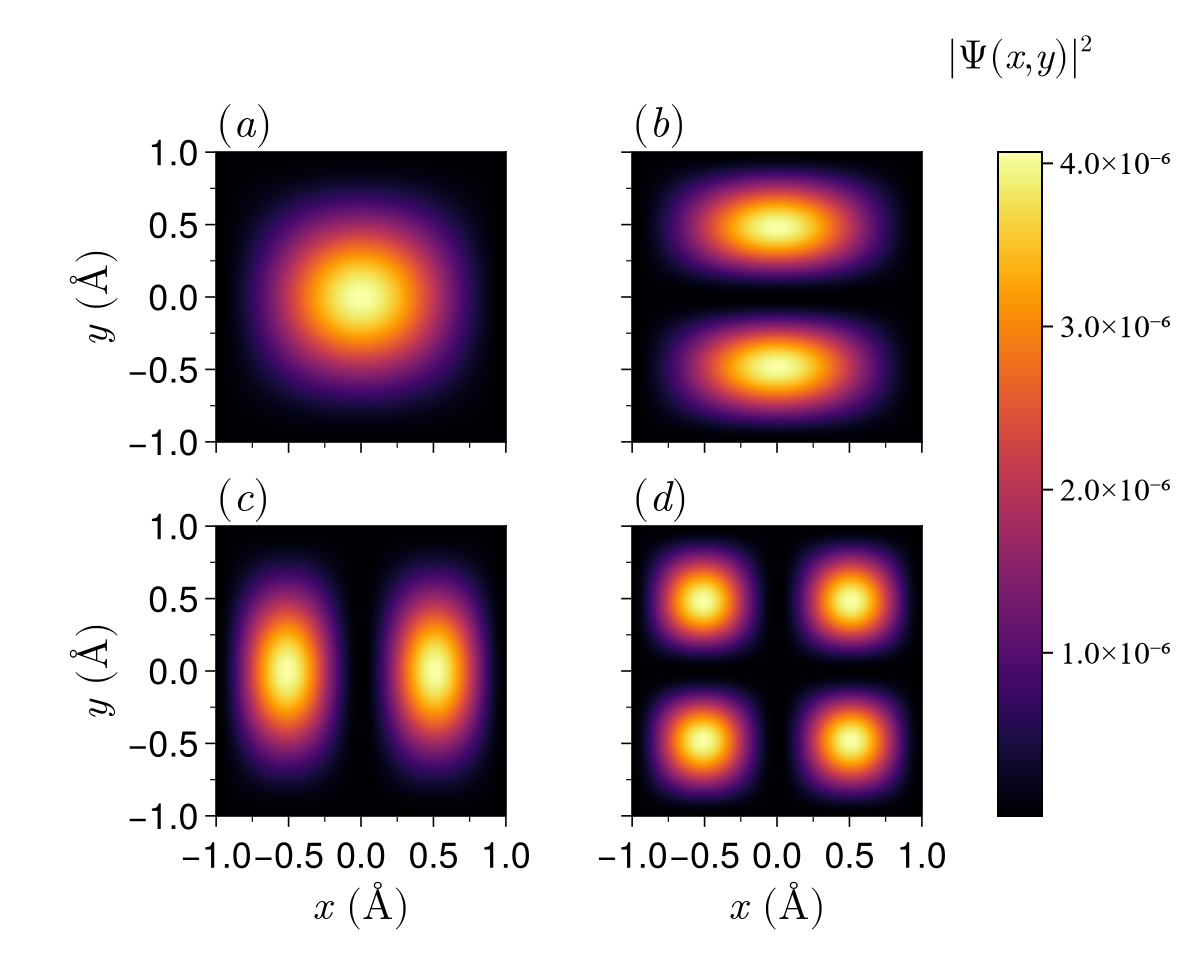

In [ ]:


CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        xlabelsize = 21,
        ylabelsize = 21,
        titlesize = 22,
        xticklabelsize = 18,
        yticklabelsize = 18,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = true,
        yminorticksvisible = true,
        xminortickwidth = 0.6,
        yminortickwidth = 0.6,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xticklabelpad = 3,
        yticklabelpad = 3,
    ),
))

fig = Figure(resolution = (600, 480), backgroundcolor = :white)

x = range(-1, 1, length = Nx)
y = range(-1, 1, length = Ny)

ax1 = Axis(fig[1,1], ylabel = L"y\ (\AA)", aspect = 1,
    title = L"(a)", titlealign = :left, titlegap = 2)

ax2 = Axis(fig[1,2], aspect = 1,
    title = L"(b)", titlealign = :left, titlegap = 2)

ax3 = Axis(fig[2,1], xlabel = L"x\ (\AA)", ylabel = L"y\ (\AA)", aspect = 1,
    title = L"(c)", titlealign = :left, titlegap = 2)

ax4 = Axis(fig[2,2], xlabel = L"x\ (\AA)", aspect = 1,
    title = L"(d)", titlealign = :left, titlegap = 2)



cmap = :inferno

hm1 = heatmap!(ax1, x, y, ψ11 .^2; colormap = cmap, rasterize = true)
hm2 = heatmap!(ax2, x, y, ψ12 .^2; colormap = cmap, rasterize = true)
hm3 = heatmap!(ax3, x, y, ψ21 .^2; colormap = cmap, rasterize = true)
hm4 = heatmap!(ax4, x, y, ψ22 .^2; colormap = cmap, rasterize = true)

# Link axes
CairoMakie.linkxaxes!(ax1, ax2, ax3, ax4)
CairoMakie.linkyaxes!(ax1, ax2, ax3, ax4)

# Hide redundant decorations, keep tick marks
CairoMakie.hidexdecorations!(ax1, ticks = false, minorticks = false)
CairoMakie.hidexdecorations!(ax2, ticks = false, minorticks = false)
CairoMakie.hideydecorations!(ax2, ticks = false, minorticks = false)
CairoMakie.hideydecorations!(ax4, ticks = false, minorticks = false)

# Colorbar label
Label(fig[0, 3], L"|\Psi(x,y)|^2",
    fontsize = 20,
    font = "Times New Roman",
    tellwidth = false,
    halign = :center,
)

Colorbar(fig[1:2, 3], hm1,
    ticklabelsize = 16,
    ticklabelfont = "Times New Roman",
    vertical = true,
    flipaxis = true,
    height = Relative(1.0),
    width = 22,
    labelpadding = 3,
    tellheight = false,
)

CairoMakie.colgap!(fig.layout, 18)
CairoMakie.rowgap!(fig.layout, 12)

save("2D_Anharmonic_Oscillator_Eigenstates_20000.pdf", fig)

fig